In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('archive/heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [5]:
df = df.drop_duplicates(keep=False)

In [6]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

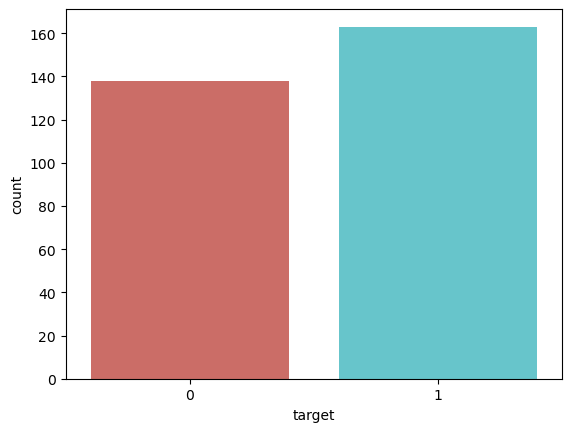

In [7]:
sns.countplot(x='target',data=df, palette='hls')
plt.show()
#plt.savefig('count_plot')

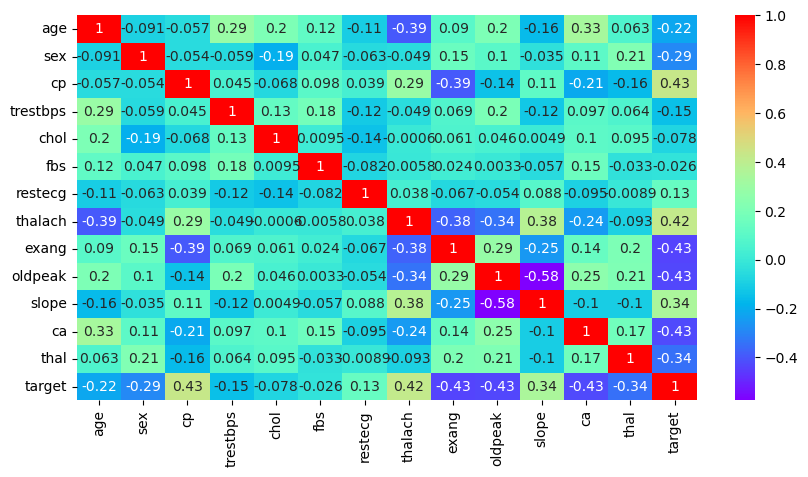

In [8]:
plt.figure(figsize = (10,5))
sns.heatmap(df.corr(), annot = True, cmap="rainbow")
plt.show()

In [9]:
X = df.drop(["target"],axis =1)
y = df["target"]

# Oversampling

In [10]:
from imblearn.over_sampling import SMOTE

# FS

In [11]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif

In [12]:
sm = SMOTE(random_state = 2)
X_res, y_res = sm.fit_resample(X,y)

In [13]:
selector = SelectKBest(f_classif, k=8) # k is the number of features to be selected
X_new = selector.fit_transform(X_res, y_res)

In [15]:
selected_features = df.columns[:-1][selector.get_support()]
print("\nSelected Features:")
print(selected_features)


Selected Features:
Index(['sex', 'cp', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal'], dtype='object')


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(X_new, y_res, test_size=0.20, random_state=42)
X_train.shape, y_train.shape, X_valid.shape, y_valid.shape

((260, 8), (260,), (66, 8), (66,))

In [17]:
from sklearn.metrics import accuracy_score # for calculating accuracy of model
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score,roc_auc_score

In [18]:
ML_Model = []
accuracy = []
precision = []
recall = []
f1score = []
auc = []

#function to call for storing the results
def storeResults(model, a,b,c,d,e):
    ML_Model.append(model)
    accuracy.append(round(a, 3))
    precision.append(round(b, 3))
    recall.append(round(c, 3))
    f1score.append(round(d, 3))
    auc.append(round(e,3))

# Naive Bayes

In [19]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, y_train)

y_pred    = nb.predict(X_valid)

nb_acc = accuracy_score(y_pred, y_valid)
nb_prec = precision_score(y_pred, y_valid,average='weighted')
nb_rec = recall_score(y_pred, y_valid,average='weighted')
nb_f1 = f1_score(y_pred, y_valid,average='weighted')
nb_auroc = roc_auc_score(y_train, nb.predict_proba(X_train)[:, 1])

In [20]:
storeResults('NaiveBayes',nb_acc,nb_prec,nb_rec,nb_f1,nb_auroc)

# SVM

In [21]:
from sklearn import svm
svc = svm.SVC(decision_function_shape='ovo',probability=True)
svc.fit(X_train, y_train)

y_pred    = svc.predict(X_valid)

svc_acc = accuracy_score(y_pred, y_valid)
svc_prec = precision_score(y_pred, y_valid,average='weighted')
svc_rec = recall_score(y_pred, y_valid,average='weighted')
svc_f1 = f1_score(y_pred, y_valid,average='weighted')
svc_auroc = roc_auc_score(y_train, svc.predict_proba(X_train)[:, 1])

In [22]:
storeResults('SVM',svc_acc,svc_prec,svc_rec,svc_f1,svc_auroc)

# XGBoost

In [23]:
from xgboost import XGBClassifier
xgb = XGBClassifier()
xgb.fit(X_train, y_train)

y_pred    = xgb.predict(X_valid)

xgb_acc = accuracy_score(y_pred, y_valid)
xgb_prec = precision_score(y_pred, y_valid,average='weighted')
xgb_rec = recall_score(y_pred, y_valid,average='weighted')
xgb_f1 = f1_score(y_pred, y_valid,average='weighted')
xgb_auroc = roc_auc_score(y_train, xgb.predict_proba(X_train)[:, 1])

In [24]:
storeResults('XGBoost',xgb_acc,xgb_prec,xgb_rec,xgb_f1,xgb_auroc)

# Adaboost

In [25]:
from sklearn.ensemble import AdaBoostClassifier
ada = AdaBoostClassifier(n_estimators=100, algorithm="SAMME", random_state=0)

ada.fit(X_train, y_train)

y_pred    = ada.predict(X_valid)

ada_acc = accuracy_score(y_pred, y_valid)
ada_prec = precision_score(y_pred, y_valid,average='weighted')
ada_rec = recall_score(y_pred, y_valid,average='weighted')
ada_f1 = f1_score(y_pred, y_valid,average='weighted')
ada_auroc = roc_auc_score(y_train, ada.predict_proba(X_train)[:, 1])

In [26]:
storeResults('AdaBoost',ada_acc,ada_prec,ada_rec,ada_f1,ada_auroc)

# Bagging Classifier

In [27]:
from sklearn.ensemble import BaggingClassifier
bag = BaggingClassifier(ada,n_estimators=10, random_state=0)

bag.fit(X_train, y_train)

y_pred    = bag.predict(X_valid)

bag_acc = accuracy_score(y_pred, y_valid)
bag_prec = precision_score(y_pred, y_valid,average='weighted')
bag_rec = recall_score(y_pred, y_valid,average='weighted')
bag_f1 = f1_score(y_pred, y_valid,average='weighted')
bag_auroc = roc_auc_score(y_train, bag.predict_proba(X_train)[:, 1])

In [28]:
storeResults('Bagging',bag_acc,bag_prec,bag_rec,bag_f1,bag_auroc)

# Decision Tree

In [29]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()

dt.fit(X_train, y_train)

y_pred    = dt.predict(X_valid)

dt_acc = accuracy_score(y_pred, y_valid)
dt_prec = precision_score(y_pred, y_valid,average='weighted')
dt_rec = recall_score(y_pred, y_valid,average='weighted')
dt_f1 = f1_score(y_pred, y_valid,average='weighted')
dt_auroc = roc_auc_score(y_train, dt.predict_proba(X_train)[:, 1])

In [30]:
storeResults('DecisionTree',dt_acc,dt_prec,dt_rec,dt_f1,dt_auroc)

# KNN

In [31]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train, y_train)

y_pred    = knn.predict(X_valid)

knn_acc = accuracy_score(y_pred, y_valid)
knn_prec = precision_score(y_pred, y_valid,average='weighted')
knn_rec = recall_score(y_pred, y_valid,average='weighted')
knn_f1 = f1_score(y_pred, y_valid,average='weighted')
knn_auroc = roc_auc_score(y_train, knn.predict_proba(X_train)[:, 1])

In [32]:
storeResults('KNN',knn_acc,knn_prec,knn_rec,knn_f1,knn_auroc)

# Random Forest

In [33]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()

rf.fit(X_train, y_train)

y_pred    = rf.predict(X_valid)

rf_acc = accuracy_score(y_pred, y_valid)
rf_prec = precision_score(y_pred, y_valid,average='weighted')
rf_rec = recall_score(y_pred, y_valid,average='weighted')
rf_f1 = f1_score(y_pred, y_valid,average='weighted')
rf_auroc = roc_auc_score(y_train, rf.predict_proba(X_train)[:, 1])

In [34]:
storeResults('RandomForest',rf_acc,rf_prec,rf_rec,rf_f1,rf_auroc)

# LogisticRegression

In [35]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(multi_class='ovr', solver='liblinear')
lr.fit(X_train, y_train)

y_pred    = lr.predict(X_valid)

lr_acc = accuracy_score(y_pred, y_valid)
lr_prec = precision_score(y_pred, y_valid,average='weighted')
lr_rec = recall_score(y_pred, y_valid,average='weighted')
lr_f1 = f1_score(y_pred, y_valid,average='weighted')
lr_auroc = roc_auc_score(y_train, lr.predict_proba(X_train)[:, 1])

In [36]:
storeResults('LogisticResgression',lr_acc,lr_prec,lr_rec,lr_f1,lr_auroc)

# Voting Classifier

In [37]:
from sklearn.ensemble import VotingClassifier

clf = VotingClassifier(estimators=[('SVM', svc),('DT', dt), ('RF', rf), ('KNN', knn),('NB', nb),('XGB', xgb), ('Ada', ada), ('BG', bag),('LR',lr)], voting='soft')

clf.fit(X_train, y_train)

y_pred    = clf.predict(X_valid)

vot_acc = accuracy_score(y_pred, y_valid)
vot_prec = precision_score(y_pred, y_valid,average='weighted')
vot_rec = recall_score(y_pred, y_valid,average='weighted')
vot_f1 = f1_score(y_pred, y_valid,average='weighted')
vot_auroc = roc_auc_score(y_train, clf.predict_proba(X_train)[:, 1])

In [38]:
storeResults('Voting',vot_acc,vot_prec,vot_rec,vot_f1,vot_auroc)

# Extension

In [39]:
from sklearn.ensemble import StackingClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
bdt = AdaBoostClassifier(
    DecisionTreeClassifier(max_depth=1), algorithm="SAMME", n_estimators=200
)
tree = ExtraTreesClassifier()
estimators = [('BoostedDT', bdt),('ET', tree)]

model = StackingClassifier(estimators=estimators, final_estimator=LGBMClassifier(n_estimators=10))

In [40]:
model.fit(X_train, y_train)

y_pred    = model.predict(X_valid)

stac_acc = accuracy_score(y_pred, y_valid)
stac_prec = precision_score(y_pred, y_valid,average='weighted')
stac_rec = recall_score(y_pred, y_valid,average='weighted')
stac_f1 = f1_score(y_pred, y_valid,average='weighted')
stac_auroc = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])

[LightGBM] [Info] Number of positive: 33, number of negative: 33
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000061 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 44
[LightGBM] [Info] Number of data points in the train set: 66, number of used features: 2
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with posi

In [41]:
storeResults('Extension',stac_acc,stac_prec,stac_rec,stac_f1,stac_auroc)

# Comparison

In [42]:
#creating dataframe
result = pd.DataFrame({ 'ML Model' : ML_Model,
                        'Accuracy' : accuracy,
                       'Precision': precision,
                       'Recall'   : recall, 
                       'F1_score' : f1score
                        
                      }) 

In [43]:
result

,ML Model,Accuracy,Precision,Recall,F1_score
0,NaiveBayes,0.848,0.850,0.848,0.849
1,SVM,0.682,0.686,0.682,0.682
2,XGBoost,0.818,0.820,0.818,0.818
3,AdaBoost,0.833,0.845,0.833,0.834
4,Bagging,0.818,0.826,0.818,0.819
5,DecisionTree,0.788,0.790,0.788,0.788
6,KNN,0.727,0.729,0.727,0.728
7,RandomForest,0.864,0.868,0.864,0.864
8,LogisticResgression,0.864,0.864,0.864,0.864
9,Voting,0.818,0.818,0.818,0.818


# Modelling

In [44]:
import joblib
filename = 'models/model_anova.sav'
joblib.dump(model, filename)

['models/model_anova.sav']

# Graph

In [46]:
classifier = ML_Model
y_pos = np.arange(len(classifier))

# Accuracy

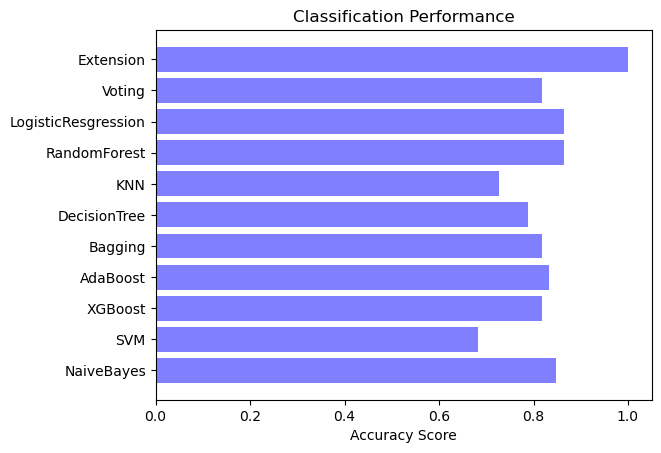

In [47]:
import matplotlib.pyplot as plt2
plt2.barh(y_pos, accuracy, align='center', alpha=0.5,color='blue')
plt2.yticks(y_pos, classifier)
plt2.xlabel('Accuracy Score')
plt2.title('Classification Performance')
plt2.show()

# Precision

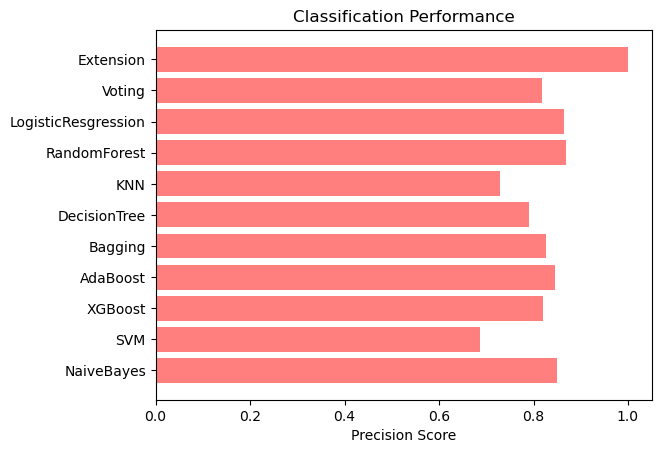

In [48]:
plt2.barh(y_pos, precision, align='center', alpha=0.5,color='red')
plt2.yticks(y_pos, classifier)
plt2.xlabel('Precision Score')
plt2.title('Classification Performance')
plt2.show()

# Recall

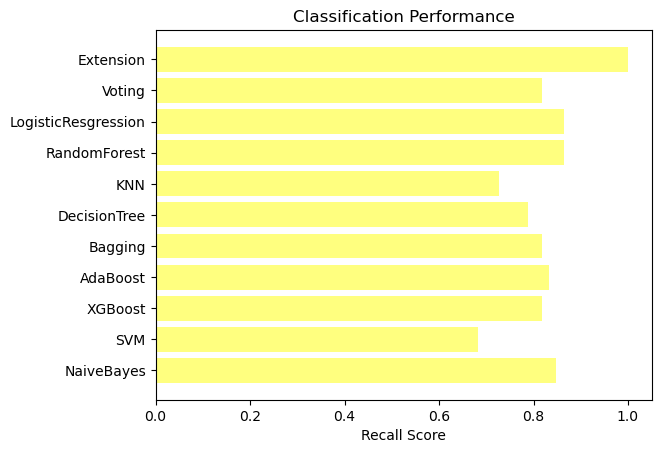

In [49]:
plt2.barh(y_pos, recall, align='center', alpha=0.5,color='yellow')
plt2.yticks(y_pos, classifier)
plt2.xlabel('Recall Score')
plt2.title('Classification Performance')
plt2.show()

# F1 Score

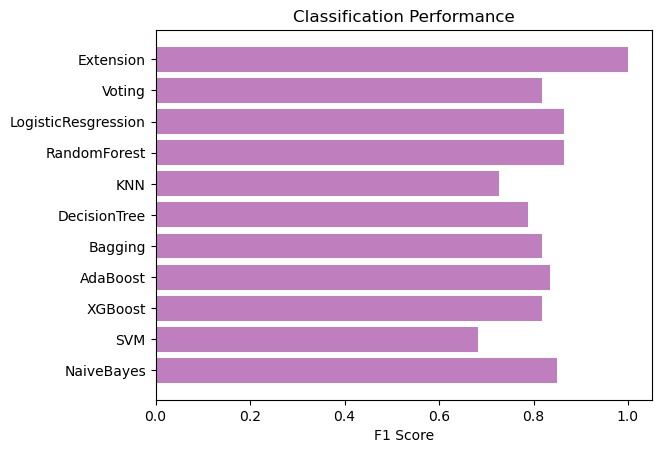

In [50]:
plt2.barh(y_pos, f1score, align='center', alpha=0.5,color='purple')
plt2.yticks(y_pos, classifier)
plt2.xlabel('F1 Score')
plt2.title('Classification Performance')
plt2.show()

# AUC Score

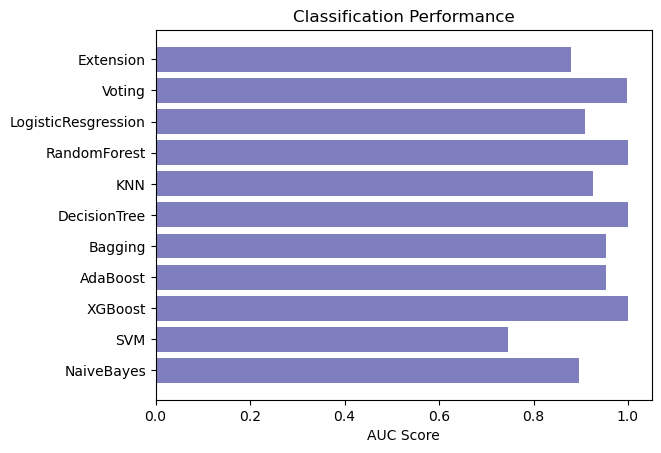

In [51]:
plt2.barh(y_pos, auc, align='center', alpha=0.5,color='navy')
plt2.yticks(y_pos, classifier)
plt2.xlabel('AUC Score')
plt2.title('Classification Performance')
plt2.show()